# Cosine similarity and distance matrices

Cosine similarity measures the **angle** between two vectors, ignoring their length:

$$\text{sim}(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}, \qquad \text{dist}(a, b) = 1 - \text{sim}(a, b)$$

It is the standard similarity for text embeddings and TF-IDF vectors, where the direction carries the meaning and the magnitude mostly reflects document length.

This notebook computes the pairwise matrix three ways (from scratch, SciPy, scikit-learn), checks that they agree, and then uses it to find similar documents.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist, cosine
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import cosine_similarity

## 1. The given matrix
Each row is a vector.

In [2]:
A = np.array([[1, 5],
              [4, 1],
              [3, 8]])

## 2. From scratch with NumPy
Normalize every row to unit length; then the matrix product of the rows gives all pairwise cosines at once.

In [3]:
def cosine_similarity_matrix(X):
    X = np.asarray(X, dtype=float)
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    unit = X / np.where(norms == 0, 1, norms)   # guard against zero vectors
    return unit @ unit.T

S = cosine_similarity_matrix(A)
D = np.clip(1 - S, 0, None)   # clip tiny negative values from rounding
print("similarity:\n", S.round(4))
print("distance:\n", D.round(4))

similarity:
 [[1.     0.4281 0.987 ]
 [0.4281 1.     0.5677]
 [0.987  0.5677 1.    ]]
distance:
 [[0.     0.5719 0.013 ]
 [0.5719 0.     0.4323]
 [0.013  0.4323 0.    ]]


## 3. Same result with libraries

In [4]:
print("sklearn cosine_similarity  :", np.allclose(S, cosine_similarity(A)))
print("sklearn pairwise_distances :", np.allclose(D, pairwise_distances(A, metric="cosine")))
print("scipy cdist                :", np.allclose(D, cdist(A, A, metric="cosine")))
print("scipy cosine(row0, row2)   :", round(cosine(A[0], A[2]), 4), "==", round(D[0, 2], 4))

sklearn cosine_similarity  : True
sklearn pairwise_distances : True
scipy cdist                : True
scipy cosine(row0, row2)   : 0.013 == 0.013


Rows 0 and 2 point in almost the same direction (distance ≈ 0.01) even though row 2 is longer, while row 1 points elsewhere. Cosine ignores magnitude.

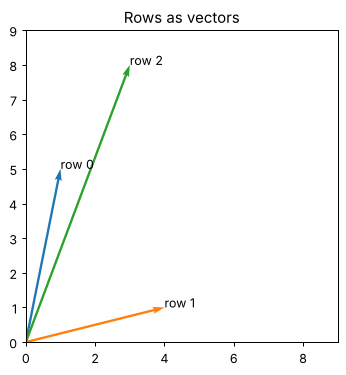

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for i, (u, v) in enumerate(A):
    ax.quiver(0, 0, u, v, angles="xy", scale_units="xy", scale=1, color=f"C{i}")
    ax.annotate(f"row {i}", (u, v))
ax.set(xlim=(0, 9), ylim=(0, 9), title="Rows as vectors", aspect="equal")

## 4. Application: finding similar documents
Turn short texts into TF-IDF vectors and rank them by cosine similarity.

[0] -> [1] (0.22)  Python is a popular programming language for ...
[1] -> [0] (0.22)  Pandas and NumPy are Python libraries for dat...
[2] -> [3] (0.13)  The stock market fell as interest rates rose...
[3] -> [2] (0.13)  Central banks raised interest rates to fight ...
[4] -> [0] (0.09)  Machine learning models are trained on data...


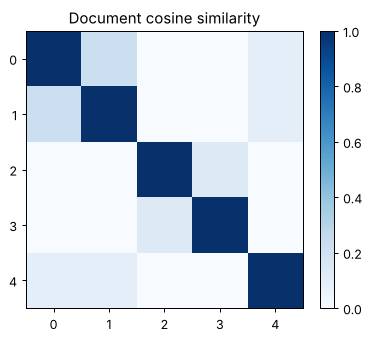

In [6]:
docs = [
    "Python is a popular programming language for data science",
    "Pandas and NumPy are Python libraries for data analysis",
    "The stock market fell as interest rates rose",
    "Central banks raised interest rates to fight inflation",
    "Machine learning models are trained on data",
]
tfidf = TfidfVectorizer(stop_words="english").fit_transform(docs)
sim = cosine_similarity(tfidf)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(sim, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(docs)), yticks=range(len(docs)), title="Document cosine similarity")
fig.colorbar(im)

for i, doc in enumerate(docs):
    j = np.argsort(sim[i])[-2]          # most similar other document
    print(f"[{i}] -> [{j}] ({sim[i, j]:.2f})  {doc[:45]}...")

## Notes

- Cosine **distance** is not a true metric (it violates the triangle inequality); use angular distance `arccos(sim) / π` if you need one.
- For large collections, normalize vectors once and use a nearest-neighbour index (e.g. FAISS) instead of the full n×n matrix.